In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view

In [3]:

from sklearn.metrics import mean_absolute_error


In [4]:
ticker = "DX-Y.NYB"
data = yf.download(ticker, start="2015-01-01", end="2026-01-01")

price = data["Close"].dropna()

[*********************100%***********************]  1 of 1 completed


In [5]:
transformed_price =np.log(price).dropna().values.ravel()

In [6]:
L=2
K=4
P=0.2

In [7]:
transformed_price.shape

(2767,)

In [8]:
def horizon(x, L, N):
    x = np.asarray(x).ravel()
    windows = sliding_window_view(x, L)
    X = windows[:len(x) - L - N + 1]
    y = x[L + N - 1 : L + N - 1 + len(X)]
    
    return X, y

In [9]:
gmae = []

for N in range(1, K + 1):
    X, y = horizon(transformed_price, L, N)
    split = int((1 - P) * len(X))
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]

    model = KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    errors = np.abs(y_test - y_pred)

    gmae_N = np.exp(np.mean(np.log(errors + 1e-12)))
    gmae.append(gmae_N)

    print(f"N = {N}, GMAE = {gmae_N:.6e}")


N = 1, GMAE = 2.403264e-03
N = 2, GMAE = 3.372196e-03
N = 3, GMAE = 4.086612e-03
N = 4, GMAE = 4.948757e-03


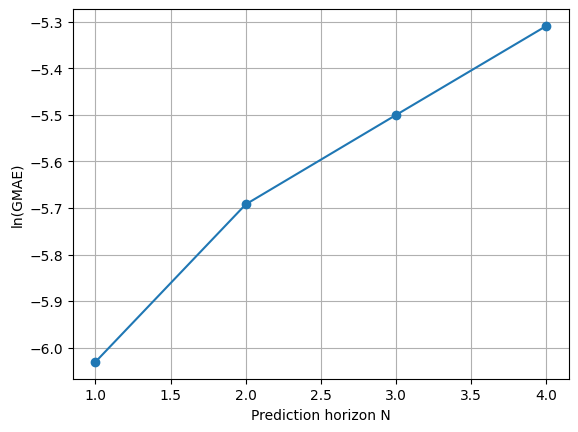

In [10]:
N_vals = np.arange(1, K+1)
log_gmae = np.log(gmae)
plt.plot(N_vals, log_gmae, 'o-')
plt.xlabel("Prediction horizon N")
plt.ylabel("ln(GMAE)")
plt.grid(True)
plt.show()


In [11]:
import numpy as np
from sklearn.linear_model import LinearRegression
n = np.arange(1, K+1).reshape(-1, 1)                   
reg = LinearRegression().fit(n, np.log(gmae) )
LLE = reg.coef_[0]

print("largest Lyapunov exponent λ =", LLE)

largest Lyapunov exponent λ = 0.23590777342467328


# TAIL EXPONENT

I used the paper mentioned here to find the tail exponent of time series data.<br>
Link:- https://dept.stat.lsa.umich.edu/~sstoev/max-spectrum-dep.pdf

In [12]:
returns = np.log(price / price.shift(1)).dropna().values
X = np.abs(returns)
X = X[X > 0]

In [13]:
def block_maxima(x, block_size):
    number_blocks = len(x) // block_size
    if number_blocks < 2:             
        return None

    maxima = np.empty(number_blocks)
    for i in range(number_blocks):
        block = x[i*block_size:(i+1)*block_size]
        if len(block) == block_size:
            maxima[i]=np.max(block)

    positives = []
    for i in range(len(maxima)):
        if(maxima[i]>0):
            positives.append(maxima[i])
    maxima = np.array(positives)        
    if len(maxima) < 2:
        return None

    return np.array(maxima)


In [14]:
def max_spectrum(x, j_min=2,j_max=None):
    js = []
    Yj = []

    if j_max is None:
        j_max = int(np.floor(np.log2(len(x)))) - 2

    for j in range(j_min, j_max + 1):
        m = 2 ** j
        maxima = block_maxima(x, m)

        if maxima is None:
            continue

        js.append(j)
        Yj.append(np.mean(np.log2(maxima)))

    if len(js) < 2:
        print("not possible")
        raise ValueError("no valid scales")

    return np.array(js), np.array(Yj)


In [15]:
js, Yj = max_spectrum(X, j_min=2)


In [16]:
print("Scales j:", js)
print("Yj:", Yj)

Scales j: [2 3 4 5 6 7 8 9]
Yj: [-7.51308313 -7.16419611 -6.85811866 -6.6635197  -6.44347504 -6.29191896
 -6.11498494 -5.84625279]


In [17]:
reg = LinearRegression().fit(js.reshape(-1, 1), Yj)
alpha = 1 / reg.coef_[0]
print("tail exponent =", alpha)


tail exponent = 4.460371504958942


### Tail Exponent of multiple stocks

In [18]:
cringe = ["DX-Y.NYB","^IXIC","^GSPC","NVDA","AMZN","GC=F"]

In [19]:
for i in cringe:
    data =yf.download(i, start="2015-01-01", end="2026-01-01")
    price = data["Close"]
    returns = np.log(price / price.shift(1)).dropna().values
    X = np.abs(returns)
    X = X[X > 0]
    js,yj = max_spectrum(X,j_min=2)
    reg = LinearRegression().fit(js.reshape(-1, 1), yj)
    alpha = 1 / reg.coef_[0]
    print(f"tail exponent for stock {i}:", alpha)

[*********************100%***********************]  1 of 1 completed

tail exponent for stock DX-Y.NYB: 4.460371504958942



[*********************100%***********************]  1 of 1 completed


tail exponent for stock ^IXIC: 3.4831733400041776


[*********************100%***********************]  1 of 1 completed


...

tail exponent for stock NVDA: 2.741157998854538


[*********************100%***********************]  1 of 1 completed


tail exponent for stock AMZN: 2.906363282202168


[*********************100%***********************]  1 of 1 completed

tail exponent for stock GC=F: 4.048831330440094


[*********************100%***********************]  1 of 1 completed

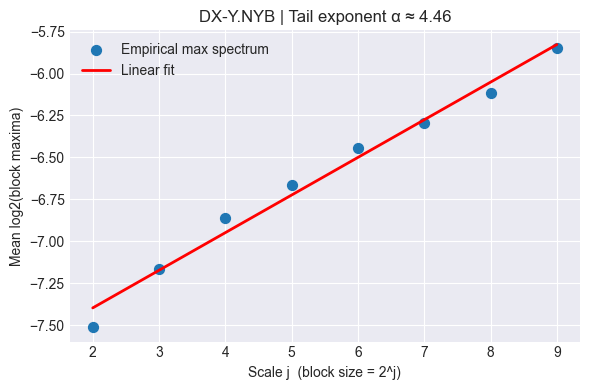

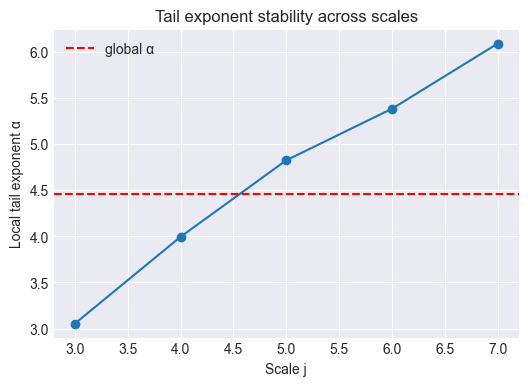

[*********************100%***********************]  1 of 1 completed


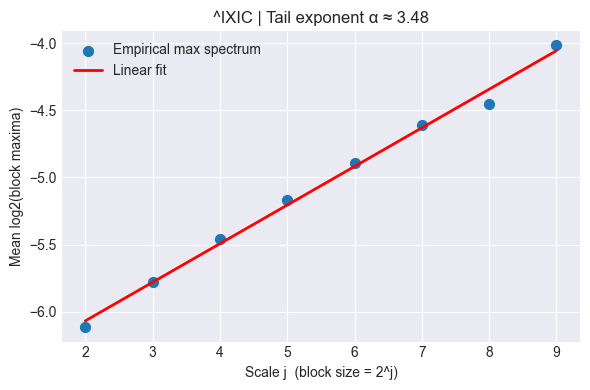

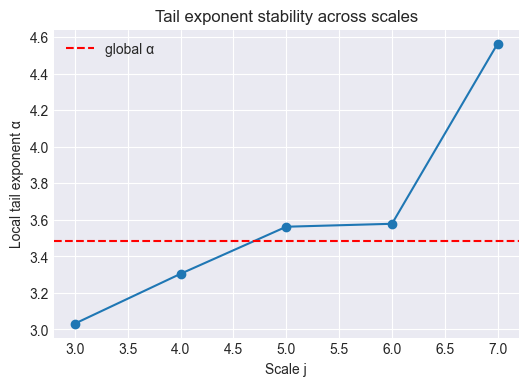

[*********************100%***********************]  1 of 1 completed


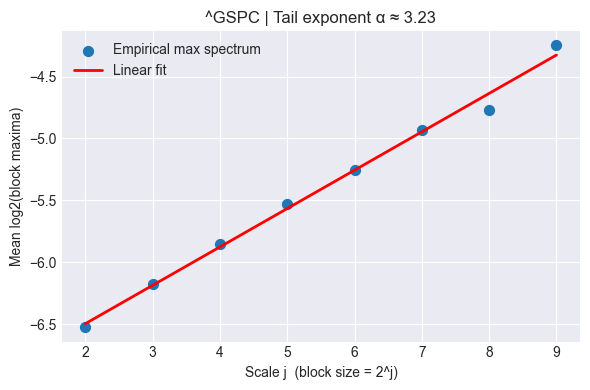

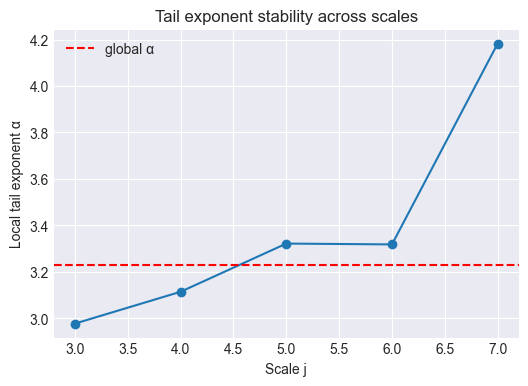

[*********************100%***********************]  1 of 1 completed


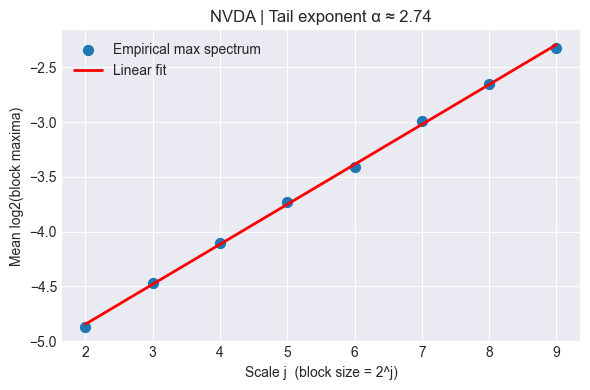

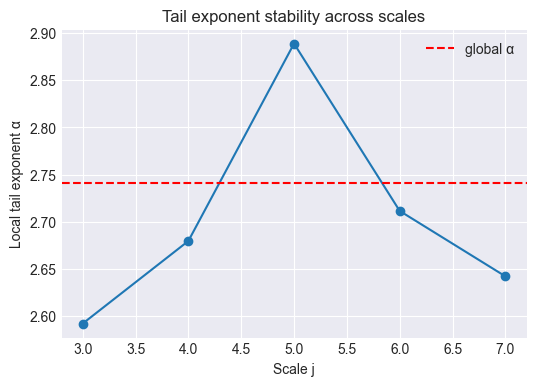

[*********************100%***********************]  1 of 1 completed


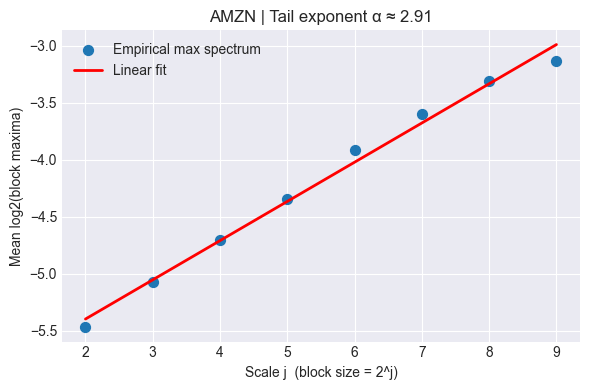

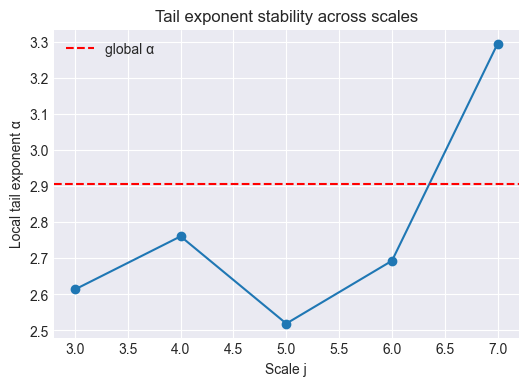

[*********************100%***********************]  1 of 1 completed


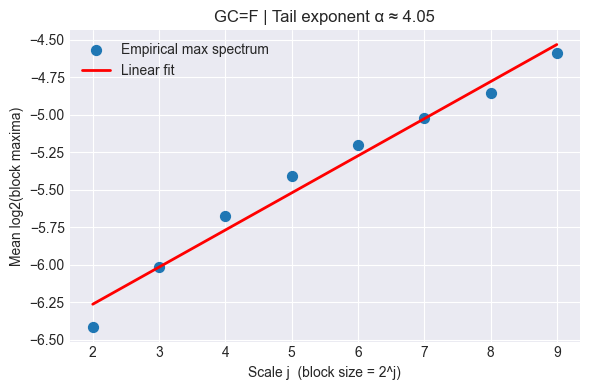

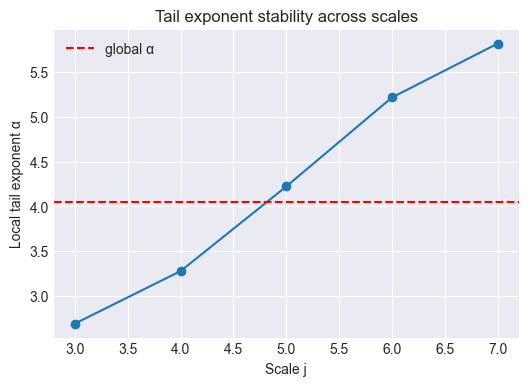

In [26]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

plt.style.use("seaborn-v0_8-darkgrid")

for i in cringe:
    data = yf.download(i, start="2015-01-01", end="2026-01-01")
    price = data["Close"]
    returns = np.log(price / price.shift(1)).dropna().values

    X = np.abs(returns)
    X = X[X > 0]

    js, yj = max_spectrum(X, j_min=2)

    reg = LinearRegression().fit(js.reshape(-1, 1), yj)
    slope = reg.coef_[0]
    intercept = reg.intercept_
    alpha = 1 / slope

    y_fit = reg.predict(js.reshape(-1, 1))

    plt.figure(figsize=(6, 4))
    plt.scatter(js, yj, label="Empirical max spectrum", s=50)
    plt.plot(js, y_fit, color="red", linewidth=2, label="Linear fit")

    plt.xlabel("Scale j  (block size = 2^j)")
    plt.ylabel("Mean log2(block maxima)")
    plt.title(f"{i} | Tail exponent α ≈ {alpha:.2f}")

    plt.legend()
    plt.tight_layout()
    plt.show()

    alphas = []
    centers = []

    for start in range(len(js) - 3):
        end = start + 3
        reg = LinearRegression().fit(
            js[start:end].reshape(-1,1),
            yj[start:end]
        )
        alphas.append(1 / reg.coef_[0])
        centers.append(js[start:end].mean())

    plt.figure(figsize=(6,4))
    plt.plot(centers, alphas, marker='o')
    plt.axhline(alpha, color='r', linestyle='--', label='global α')
    plt.xlabel("Scale j")
    plt.ylabel("Local tail exponent α")
    plt.legend()
    plt.title("Tail exponent stability across scales")
    plt.show()



With 3^j


Ticker: DX-Y.NYB
Global tail exponent α ≈ 4.044


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


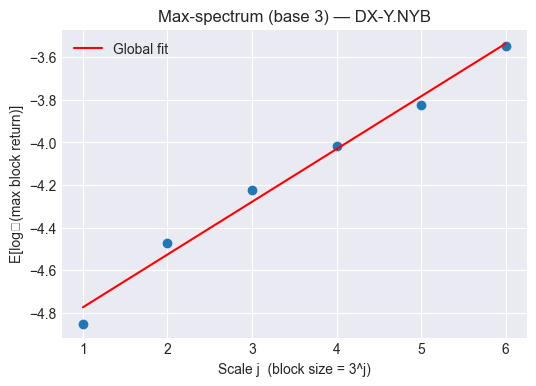

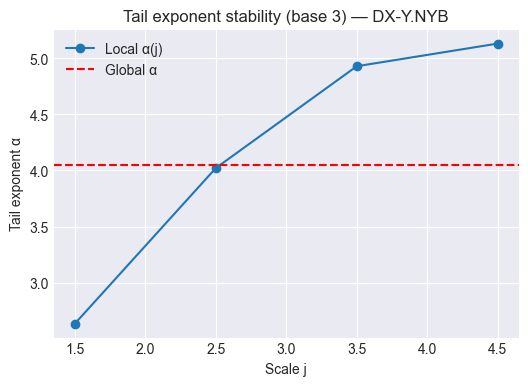


Ticker: ^IXIC
Global tail exponent α ≈ 3.130


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


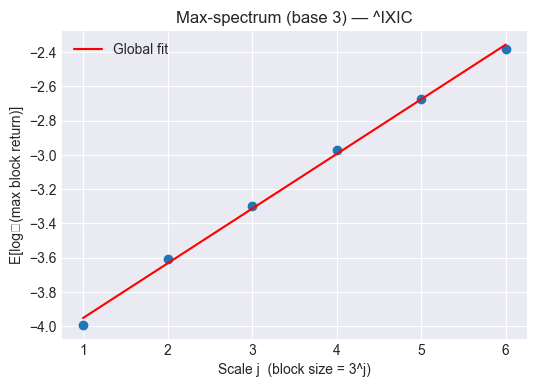

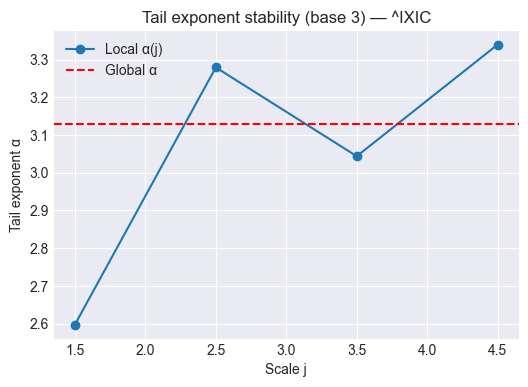


Ticker: ^GSPC
Global tail exponent α ≈ 2.889


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


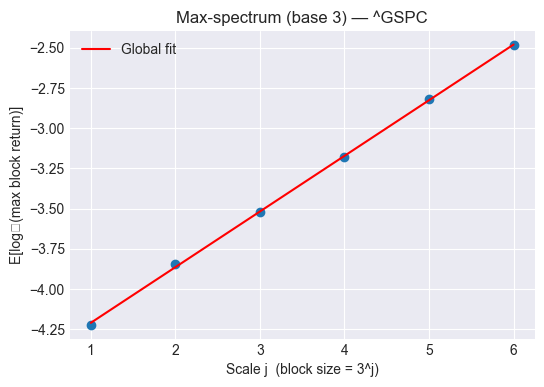

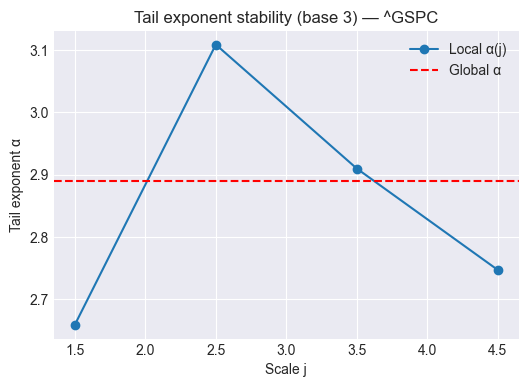


Ticker: NVDA
Global tail exponent α ≈ 2.720


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


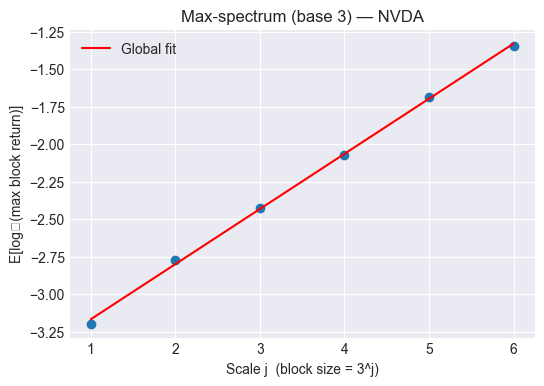

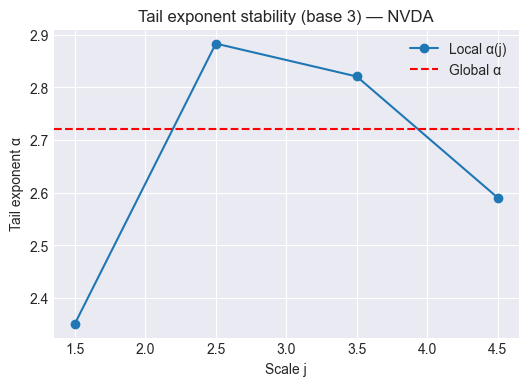


Ticker: AMZN
Global tail exponent α ≈ 2.915


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


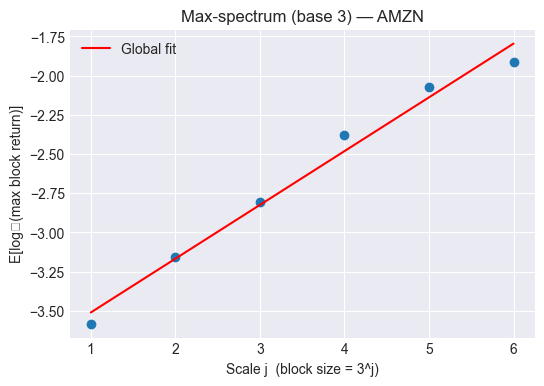

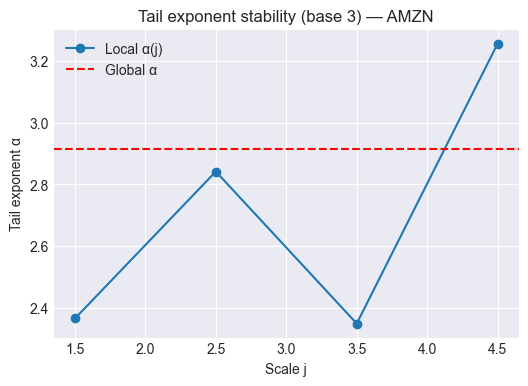


Ticker: GC=F
Global tail exponent α ≈ 3.617


C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


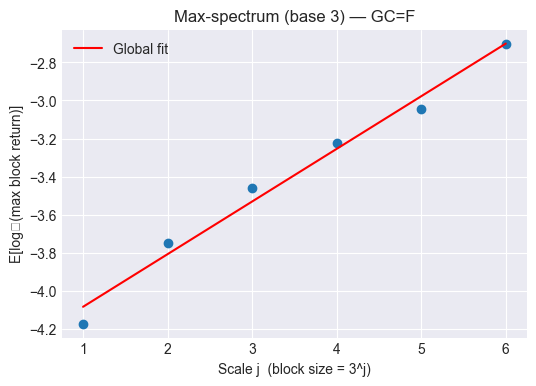

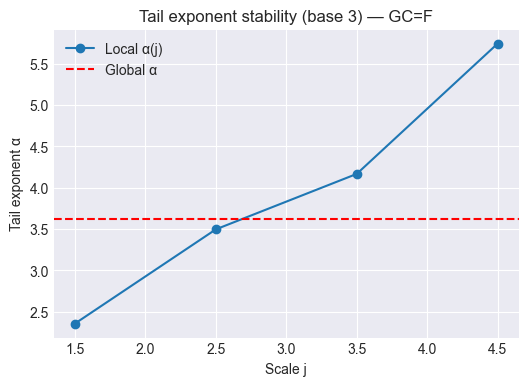

In [28]:
# ======== Base-3 Max-Spectrum Tail Estimation (Single Cell) ========

import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# -----------------------------
# Block maxima
# -----------------------------
def block_maxima(x, block_size):
    n_blocks = len(x) // block_size
    if n_blocks < 2:
        return None

    maxima = []
    for i in range(n_blocks):
        block = x[i*block_size:(i+1)*block_size]
        if len(block) == block_size:
            m = np.max(block)
            if m > 0:
                maxima.append(m)

    if len(maxima) < 2:
        return None

    return np.array(maxima)


# -----------------------------
# Max-spectrum with base 3
# -----------------------------
def max_spectrum_base3(x, j_min=1, j_max=None):
    js = []
    Yj = []

    if j_max is None:
        j_max = int(np.floor(np.log(len(x)) / np.log(3))) - 1

    for j in range(j_min, j_max + 1):
        m = 3 ** j
        maxima = block_maxima(x, m)
        if maxima is None:
            continue

        js.append(j)
        Yj.append(np.mean(np.log(maxima) / np.log(3)))  # log base 3

    if len(js) < 2:
        raise ValueError("Not enough valid scales")

    return np.array(js), np.array(Yj)


# -----------------------------
# Run for each asset
# -----------------------------
tickers = ["DX-Y.NYB", "^IXIC", "^GSPC", "NVDA", "AMZN", "GC=F"]

for ticker in tickers:
    data = yf.download(ticker, start="2015-01-01", end="2026-01-01", progress=False)
    price = data["Close"].dropna()

    returns = np.log(price / price.shift(1)).dropna().values
    X = np.abs(returns)
    X = X[X > 0]

    js, yj = max_spectrum_base3(X, j_min=1)

    # Global tail exponent
    reg = LinearRegression().fit(js.reshape(-1, 1), yj)
    alpha = 1 / reg.coef_[0]

    print(f"\nTicker: {ticker}")
    print(f"Global tail exponent α ≈ {alpha:.3f}")

    # ---- Plot max-spectrum ----
    plt.figure(figsize=(6,4))
    plt.scatter(js, yj)
    plt.plot(js, reg.predict(js.reshape(-1,1)), color="red", label="Global fit")
    plt.xlabel("Scale j  (block size = 3^j)")
    plt.ylabel("E[log₃(max block return)]")
    plt.title(f"Max-spectrum (base 3) — {ticker}")
    plt.legend()
    plt.show()

    # ---- Local α(j) stability ----
    alphas = []
    centers = []
    window = 2

    for start in range(len(js) - window):
        end = start + window
        reg_loc = LinearRegression().fit(
            js[start:end].reshape(-1,1),
            yj[start:end]
        )
        alphas.append(1 / reg_loc.coef_[0])
        centers.append(js[start:end].mean())

    plt.figure(figsize=(6,4))
    plt.plot(centers, alphas, marker='o', label="Local α(j)")
    plt.axhline(alpha, color='r', linestyle='--', label="Global α")
    plt.xlabel("Scale j")
    plt.ylabel("Tail exponent α")
    plt.title(f"Tail exponent stability (base 3) — {ticker}")
    plt.legend()
    plt.show()
